# 01 — Retrieval: choosing the search method

The assistant answers from the passages that search returns, so retrieval sets the ceiling for answer
quality. This notebook compares three retrieval methods ("arms") on the corpus built in notebook 00 and
answers two questions:

| Part | Question |
|---|---|
| **A** | Which arm puts a correct passage in the top 3 most often (**Hit@3**), and at what cost? |
| **B** | Can the search score alone tell answerable from unanswerable questions? |

**Inputs:** the corpus `processed_data/chunks.jsonl` produced by notebook 00 (verified by SHA-256), and
168 evaluation questions written out in this notebook. **Runtime:** Colab **T4 GPU**, ≈ 6 min on a
fresh runtime, most of it the one-time model download (sizes are reported in the results). An `HF_TOKEN` in
Colab Secrets is optional.

In [1]:
# ==== Setup ==================================================================
# Install only what a fresh Colab runtime is missing (most packages are preinstalled).
import importlib.util
import subprocess
import sys

REQUIRED = {  # pip name -> import name; only checked here (importing torch is slow)
    "sentence-transformers>=3.0": "sentence_transformers",
    "transformers>=4.44": "transformers",
    "torch": "torch",
    "seaborn": "seaborn",
}
missing = [pip for pip, mod in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", ", ".join(missing), flush=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

In [2]:
# ==== Configuration & shared helpers =========================================
import hashlib
import json
import logging
import urllib.request
import os
import re
import time
import warnings
from collections import Counter
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from IPython.display import Markdown, display

# Keep the output readable: model-loading warnings and progress bars are noise here.
warnings.filterwarnings("ignore", category=UserWarning)
for name in ("sentence_transformers", "transformers", "huggingface_hub"):
    logging.getLogger(name).setLevel(logging.ERROR)
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
sns.set_theme(style="whitegrid", context="notebook")

# Fixed seed + resample count: every CI in this notebook is reproducible.
CORPUS_URL = "https://raw.githubusercontent.com/tal-mat/knowledge-assistant/main/processed_data/chunks.jsonl"
CORPUS_SHA256_PREFIX = "0946af1b8e105a46"  # the corpus built by notebook 00
BOOTSTRAP_SEED, BOOTSTRAP_N = 20251011, 1000
# Hebrew + Latin word tokens. Used by BM25 and by the lexical-overlap signal in Part B.
TOKEN_RE = re.compile(r"[\w\u0590-\u05ff]+", re.UNICODE)
# Candidates per query, candidates re-scored by a reranker (all of them), and the RRF damping constant
# (standard 60). RERANK_N cannot exceed TOP_K_PER_QUERY: a reranker only sees the retrieved candidates.
TOP_K_PER_QUERY, RERANK_N, RRF_K = 10, 10, 60

# Exact model ids — changing any of them is a different experiment.
BGE_M3_MODEL = "BAAI/bge-m3"
BGE_RERANKER = "BAAI/bge-reranker-v2-m3"
QWEN_EMBED_MODEL = "Qwen/Qwen3-Embedding-0.6B"
QWEN_RERANKER = "Qwen/Qwen3-Reranker-0.6B"
# Qwen3-Embedding is instruction-tuned: queries get a task prefix, documents do not.
QWEN_QUERY_INSTRUCTION = (
    "Given an employee question about company policies and guides, "
    "retrieve the most relevant internal document passage"
)


def load_hf_token() -> bool:
    """Optional HF_TOKEN from the environment or Colab Secrets (avoids Hub rate limits)."""
    token = (os.environ.get("HF_TOKEN") or "").strip()
    if not token:
        try:
            from google.colab import userdata  # type: ignore
            token = (userdata.get("HF_TOKEN") or "").strip()
        except Exception:
            token = ""
    if token:
        os.environ["HF_TOKEN"] = os.environ["HUGGING_FACE_HUB_TOKEN"] = token
    return bool(token)


HF_TOKEN_SET = load_hf_token()
try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    DEVICE = "cpu"


def show_md(text: str) -> None:
    """Render Markdown built from computed values (no number in the text is typed by hand)."""
    display(Markdown(text))


def bootstrap_ci(values, *, seed: int = BOOTSTRAP_SEED, n: int = BOOTSTRAP_N) -> tuple[float, float, float]:
    """Mean and 95% percentile-bootstrap CI.

    Resamples the per-probe 0/1 outcomes with replacement. With 120 probes a single rate hides how
    unstable it is; the CI shows whether a difference between two arms could be chance.
    (A vectorised draw would be faster but would change the RNG stream and therefore the CIs.)
    """
    v = np.asarray(values, dtype=float)
    if len(v) == 0:
        return float("nan"), float("nan"), float("nan")
    rng = np.random.default_rng(seed)
    means = np.array([rng.choice(v, size=len(v), replace=True).mean() for _ in range(n)])
    lo, hi = np.quantile(means, [0.025, 0.975])
    return float(v.mean()), float(lo), float(hi)


def bar_with_ci(df, *, x: str, y: str, lo: str, hi: str, title: str, threshold: float | None = None) -> None:
    """Bar per row with its bootstrap CI, the value on top, and an optional target line."""
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(data=df, x=x, y=y, ax=ax, color="#4C78A8", order=list(df[x]))
    ax.errorbar(range(len(df)), df[y], yerr=[df[y] - df[lo], df[hi] - df[y]], fmt="none", ecolor="black", capsize=4)
    for i, (v, top) in enumerate(zip(df[y], df[hi])):
        ax.text(i, top + 0.015, f"{v:.3f}", ha="center", va="bottom", fontsize=9)  # above the whisker
    if threshold is not None:
        ax.axhline(threshold, color="#E45756", linestyle="--", label=f"target = {threshold}")
        ax.legend()
    ax.set(title=title, ylim=(0, 1.12), xlabel="", ylabel=y)
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()


def model_cache_mb(model_id: str) -> float:
    """Size of a model in the local Hugging Face cache (NaN if it was never downloaded)."""
    d = Path.home() / ".cache" / "huggingface" / "hub" / ("models--" + model_id.replace("/", "--"))
    if not d.is_dir():
        return float("nan")
    return sum(p.stat().st_size for p in d.rglob("*") if p.is_file()) / 2**20


show_md(f"Running on `{DEVICE}` · HF token: {'set' if HF_TOKEN_SET else 'not set (optional)'}")

Running on `cuda` · HF token: set

In [3]:
# ==== Selection criteria =====================================================
# Fixed before the run, never tuned on the results below.
CRITERIA = {
    "A_CI_FLOOR": -0.03,         # A: an arm qualifies if CI-lo of its Hit@3 difference to the best arm > this
    "B_RECALL_TARGET": 0.80,     # B: share of unanswerable questions that must be caught
    "B_FALSE_ABSTAIN_MAX": 0.05, # B: max share of answerable questions wrongly refused
    "SPLIT_SEED": 7,             # B: calibration / test split
}

## Data

- **Corpus** — 200 chunks from notebook 00: 57 passages of the 15 company documents + 143 synthetic
  distractors. A chunk is embedded as its `context` (document › section) followed by its text.
- **Evaluation questions** (next, collapsed cell) — 120 *answerable* questions, each with the id of the gold
  chunk that contains the answer, and 48 *unanswerable* questions (used only in Part B), in Hebrew and English.

In [4]:
# ==== Evaluation questions ===================================================
# One tuple per probe: (probe_id, set, language, kind, question, gold chunk ids).
# answerable: the answer is in the gold chunk(s). unanswerable: no document contains the answer
#   (near_miss = a plausible company topic, far = clearly out of scope).
PROBES = [
    ('v3-001-he-en-natural', 'answerable', 'he', None, "איך מגישים בקשה לתוכנה חדשה?", ['195aafee3696-002']),
    ('v3-002-en-en-natural', 'answerable', 'en', None, "How do I request new software?", ['195aafee3696-002']),
    ('v3-003-he-en-natural', 'answerable', 'he', None, "האם מותר להתקין תוכנה שלא מופיעה ברשימה המאושרת?", ['195aafee3696-001']),
    ('v3-004-en-en-natural', 'answerable', 'en', None, "May I install software that is not on the approved list?", ['195aafee3696-001']),
    ('v3-005-he-en-natural', 'answerable', 'he', None, "אילו כלי פיתוח מאושרים?", ['195aafee3696-003']),
    ('v3-006-en-en-natural', 'answerable', 'en', None, "Which development tools are approved?", ['195aafee3696-003']),
    ('v3-007-he-en-natural', 'answerable', 'he', None, "מהו כלי ה-AI הארגוני המאושר?", ['195aafee3696-004']),
    ('v3-008-en-en-natural', 'answerable', 'en', None, "What is the approved organizational AI tool?", ['195aafee3696-004']),
    ('v3-009-he-en-natural', 'answerable', 'he', None, "האם Dropbox אישי מאושר?", ['195aafee3696-005']),
    ('v3-010-en-en-natural', 'answerable', 'en', None, "Is personal Dropbox approved?", ['195aafee3696-005']),
    ('v3-011-he-en-natural', 'answerable', 'he', None, "מה אורך הסיסמה המינימלי?", ['14c44a5a9153-001']),
    ('v3-012-en-en-natural', 'answerable', 'en', None, "What is the minimum password length?", ['14c44a5a9153-001']),
    ('v3-013-he-en-natural', 'answerable', 'he', None, "האם מותר MFA ב-SMS?", ['14c44a5a9153-002']),
    ('v3-014-en-en-natural', 'answerable', 'en', None, "Are SMS codes allowed for MFA?", ['14c44a5a9153-002']),
    ('v3-015-he-en-natural', 'answerable', 'he', None, "אחרי כמה ניסיונות כושלים ננעל החשבון?", ['14c44a5a9153-003']),
    ('v3-016-en-en-natural', 'answerable', 'en', None, "After how many failed logins is the account locked?", ['14c44a5a9153-003']),
    ('v3-017-he-en-natural', 'answerable', 'he', None, "מתי חובה להשתמש ב-VPN?", ['38d3019d10bd-001']),
    ('v3-018-en-en-natural', 'answerable', 'en', None, "When is VPN required?", ['38d3019d10bd-001']),
    ('v3-019-he-en-natural', 'answerable', 'he', None, "איך מתקינים את TovanaConnect?", ['38d3019d10bd-002']),
    ('v3-020-en-en-natural', 'answerable', 'en', None, "How do I install TovanaConnect?", ['38d3019d10bd-002']),
    ('v3-021-he-en-natural', 'answerable', 'he', None, "אחרי כמה שעות מתנתק ה-VPN אוטומטית?", ['38d3019d10bd-002']),
    ('v3-022-en-en-natural', 'answerable', 'en', None, "After how many hours does the VPN disconnect automatically?", ['38d3019d10bd-002']),
    ('v3-023-he-en-natural', 'answerable', 'he', None, "מה משמעות שגיאת E-401 ב-VPN?", ['38d3019d10bd-003']),
    ('v3-024-en-en-natural', 'answerable', 'en', None, "What does VPN error E-401 mean?", ['38d3019d10bd-003']),
    ('v3-025-he-en-natural', 'answerable', 'he', None, "מה תקרת הארוחות בנסיעה פנים-ארצית לפי Travel Policy?", ['d21fafd760ec-002']),
    ('v3-026-en-en-natural', 'answerable', 'en', None, "What is the domestic meal cap in the Travel Policy?", ['d21fafd760ec-002']),
    ('v3-027-he-en-natural', 'answerable', 'he', None, "מה ה-per diem בנסיעה לחו״ל?", ['d21fafd760ec-003']),
    ('v3-028-en-en-natural', 'answerable', 'en', None, "What is the international per diem?", ['d21fafd760ec-003']),
    ('v3-029-he-en-natural', 'answerable', 'he', None, "מה תקרת המלון הרגילה בחו״ל?", ['d21fafd760ec-003']),
    ('v3-030-en-en-natural', 'answerable', 'en', None, "What is the standard hotel cap abroad?", ['d21fafd760ec-003']),
    ('v3-031-he-en-natural', 'answerable', 'he', None, "כמה ימים מראש צריך לאשר נסיעה לחו״ל?", ['d21fafd760ec-004']),
    ('v3-032-en-en-natural', 'answerable', 'en', None, "How many days ahead must foreign travel be approved?", ['d21fafd760ec-004']),
    ('v3-033-he-en-natural', 'answerable', 'he', None, "דרך מי מזמינים טיסות ומלונות?", ['d21fafd760ec-005']),
    ('v3-034-en-en-natural', 'answerable', 'en', None, "Who books flights and hotels?", ['d21fafd760ec-005']),
    ('v3-035-he-en-natural', 'answerable', 'he', None, "מה זמן התגובה של תמיכת CloudFix?", ['347f1913991f-002']),
    ('v3-036-en-en-natural', 'answerable', 'en', None, "What is CloudFix support response time?", ['347f1913991f-002']),
    ('v3-037-he-en-natural', 'answerable', 'he', None, "מתי חלון התחזוקה של CloudFix?", ['347f1913991f-003']),
    ('v3-038-en-en-natural', 'answerable', 'en', None, "When is the CloudFix maintenance window?", ['347f1913991f-003']),
    ('v3-039-he-en-natural', 'answerable', 'he', None, "מה תנאי התשלום ל-CloudFix?", ['347f1913991f-004']),
    ('v3-040-en-en-natural', 'answerable', 'en', None, "What are CloudFix payment terms?", ['347f1913991f-004']),
    ('v3-041-en-he-natural', 'answerable', 'en', None, "How many leave days for years 1–3 of tenure?", ['1486073f4bb2-003']),
    ('v3-042-he-he-natural', 'answerable', 'he', None, "כמה ימי חופשה לשנים 1–3?", ['1486073f4bb2-003']),
    ('v3-043-en-he-natural', 'answerable', 'en', None, "What is the leave accrual cap?", ['1486073f4bb2-004']),
    ('v3-044-he-he-natural', 'answerable', 'he', None, "מה תקרת צבירת ימי החופשה?", ['1486073f4bb2-004']),
    ('v3-045-en-he-natural', 'answerable', 'en', None, "When must a leave request of up to 3 days be submitted?", ['1486073f4bb2-005']),
    ('v3-046-he-he-natural', 'answerable', 'he', None, "מתי צריך להגיש בקשת חופשה של עד 3 ימים?", ['1486073f4bb2-005']),
    ('v3-047-en-he-natural', 'answerable', 'en', None, "What happens to leave days during Chol HaMoed Sukkot?", ['1486073f4bb2-006']),
    ('v3-048-he-he-natural', 'answerable', 'he', None, "מה קורה לימי חופשה בחול המועד סוכות?", ['1486073f4bb2-006']),
    ('v3-049-en-he-natural', 'answerable', 'en', None, "Which email handles leave questions?", ['1486073f4bb2-007']),
    ('v3-050-he-he-natural', 'answerable', 'he', None, "לאיזו כתובת פונים בשאלות חופשה?", ['1486073f4bb2-007']),
    ('v3-051-en-he-natural', 'answerable', 'en', None, "Does the 2025 policy replace the February 2023 WFH policy?", ['0a3104f246cc-000']),
    ('v3-052-he-he-natural', 'answerable', 'he', None, "האם מדיניות 2025 מחליפה את מדיניות פברואר 2023?", ['0a3104f246cc-000']),
    ('v3-053-en-he-natural', 'answerable', 'en', None, "How many WFH days are allowed under the 2025 policy?", ['0a3104f246cc-001']),
    ('v3-054-he-he-natural', 'answerable', 'he', None, "כמה ימי עבודה מהבית מותרים במדיניות 2025?", ['0a3104f246cc-001']),
    ('v3-055-en-he-natural', 'answerable', 'en', None, "Which day is the mandatory office day?", ['0a3104f246cc-001']),
    ('v3-056-he-he-natural', 'answerable', 'he', None, "איזה יום הוא יום משרד חובה?", ['0a3104f246cc-001']),
    ('v3-057-en-he-natural', 'answerable', 'en', None, "What is the WFH equipment grant amount?", ['0a3104f246cc-002']),
    ('v3-058-he-he-natural', 'answerable', 'he', None, "מה סכום מענק הציוד לעבודה מהבית?", ['0a3104f246cc-002']),
    ('v3-059-en-he-natural', 'answerable', 'en', None, "How many work-from-abroad days per year?", ['0a3104f246cc-003']),
    ('v3-060-he-he-natural', 'answerable', 'he', None, "כמה ימי עבודה מחו״ל מותרים בשנה?", ['0a3104f246cc-003']),
    ('v3-061-en-he-natural', 'answerable', 'en', None, "How many sick days accrue per month?", ['38fe3ee78cc1-000']),
    ('v3-062-he-he-natural', 'answerable', 'he', None, "כמה ימי מחלה נצברים בחודש?", ['38fe3ee78cc1-000']),
    ('v3-063-en-he-natural', 'answerable', 'en', None, "What is the sick-leave cap?", ['38fe3ee78cc1-000']),
    ('v3-064-he-he-natural', 'answerable', 'he', None, "מה תקרת ימי המחלה?", ['38fe3ee78cc1-000']),
    ('v3-065-en-he-natural', 'answerable', 'en', None, "From which day is a medical certificate required?", ['38fe3ee78cc1-000']),
    ('v3-066-he-he-natural', 'answerable', 'he', None, "מאיזה יום נדרש אישור רפואי?", ['38fe3ee78cc1-000']),
    ('v3-067-en-he-natural', 'answerable', 'en', None, "What is the private-car per-km rate?", ['43fb6ce705a3-002']),
    ('v3-068-he-he-natural', 'answerable', 'he', None, "כמה משלמים לק״מ ברכב פרטי?", ['43fb6ce705a3-002']),
    ('v3-069-en-he-natural', 'answerable', 'en', None, "What is the meal cap in the expense procedure?", ['43fb6ce705a3-002']),
    ('v3-070-he-he-natural', 'answerable', 'he', None, "מה תקרת הארוחות בנוהל ההחזרים?", ['43fb6ce705a3-002']),
    ('v3-071-en-he-natural', 'answerable', 'en', None, "From what amount does an expense need prior manager approval?", ['43fb6ce705a3-003']),
    ('v3-072-he-he-natural', 'answerable', 'he', None, "מאיזה סכום נדרש אישור מנהל להוצאה?", ['43fb6ce705a3-003']),
    ('v3-073-en-he-natural', 'answerable', 'en', None, "Within how many days must receipts be submitted?", ['43fb6ce705a3-004']),
    ('v3-074-he-he-natural', 'answerable', 'he', None, "תוך כמה ימים מגישים קבלות?", ['43fb6ce705a3-004']),
    ('v3-075-en-he-natural', 'answerable', 'en', None, "Who approves purchases up to NIS 5,000?", ['d7796fb6f7cf-002']),
    ('v3-076-he-he-natural', 'answerable', 'he', None, "מי מאשר רכישה עד 5,000 ₪?", ['d7796fb6f7cf-002']),
    ('v3-077-en-he-natural', 'answerable', 'en', None, "Who approves purchases over NIS 250,000?", ['d7796fb6f7cf-002']),
    ('v3-078-he-he-natural', 'answerable', 'he', None, "מי מאשר רכישה מעל 250,000 ₪?", ['d7796fb6f7cf-002']),
    ('v3-079-en-he-natural', 'answerable', 'en', None, "What are standard supplier payment terms?", ['d7796fb6f7cf-003']),
    ('v3-080-he-he-natural', 'answerable', 'he', None, "מה תנאי התשלום הסטנדרטיים לספקים?", ['d7796fb6f7cf-003']),
    ('v3-081-en-he-natural', 'answerable', 'en', None, "Which catalog must AI tools come from?", ['17fee73c152f-001']),
    ('v3-082-he-he-natural', 'answerable', 'he', None, "מאיזה קטלוג חייבים לבחור כלי AI?", ['17fee73c152f-001']),
    ('v3-083-en-he-natural', 'answerable', 'en', None, "What must not be entered into public AI tools?", ['17fee73c152f-002']),
    ('v3-084-he-he-natural', 'answerable', 'he', None, "איזה מידע אסור להזין לכלי AI ציבוריים?", ['17fee73c152f-002']),
    ('v3-085-en-he-natural', 'answerable', 'en', None, "Does customer-facing AI content need human review?", ['17fee73c152f-003']),
    ('v3-086-he-he-natural', 'answerable', 'he', None, "האם תוכן AI ללקוחות דורש בדיקה אנושית?", ['17fee73c152f-003']),
    ('v3-087-en-he-natural', 'answerable', 'en', None, "Where do you report unauthorized AI use?", ['17fee73c152f-004']),
    ('v3-088-he-he-natural', 'answerable', 'he', None, "לאן מדווחים על שימוש לא מורשה ב-AI?", ['17fee73c152f-004']),
    ('v3-089-en-he-natural', 'answerable', 'en', None, "Which system is used to order IT equipment?", ['ad3f2765b0da-000']),
    ('v3-090-he-he-natural', 'answerable', 'he', None, "דרך איזו מערכת מזמינים ציוד מחשוב?", ['ad3f2765b0da-000']),
    ('v3-091-he-bi-natural', 'answerable', 'he', None, "מה זמן התגובה לקריאת P1?", ['b3fe9199008b-000']),
    ('v3-092-en-bi-natural', 'answerable', 'en', None, "What is the P1 response time?", ['b3fe9199008b-000']),
    ('v3-093-he-bi-natural', 'answerable', 'he', None, "איפה מגישים בקשת חופשה לפי ה-FAQ?", ['c5cce790e224-000']),
    ('v3-094-en-bi-natural', 'answerable', 'en', None, "Where do new hires submit leave requests per the FAQ?", ['c5cce790e224-000']),
    ('v3-095-he-bi-natural', 'answerable', 'he', None, "לאן מדווחים על פישינג?", ['c5cce790e224-000']),
    ('v3-096-en-bi-natural', 'answerable', 'en', None, "Where is phishing reported?", ['c5cce790e224-000']),
    ('v3-097-en-he-natural', 'answerable', 'en', None, "How many WFH days did the 2023 scanned policy allow?", ['42cda623f030-000']),
    ('v3-098-he-he-natural', 'answerable', 'he', None, "כמה ימי בית התיר מסמך הסריקה מ-2023?", ['42cda623f030-000']),
    ('v3-099-en-he-natural', 'answerable', 'en', None, "Is VPN mandatory off-site under the 2025 hybrid policy?", ['0a3104f246cc-004']),
    ('v3-100-he-he-natural', 'answerable', 'he', None, "האם חובה VPN מחוץ למשרד לפי מדיניות 2025?", ['0a3104f246cc-004']),
    ('v3-101-he-en-short', 'answerable', 'he', None, "בקשת תוכנה חדשה", ['195aafee3696-002']),
    ('v3-102-en-en-short', 'answerable', 'en', None, "new software request", ['195aafee3696-002']),
    ('v3-103-he-en-short', 'answerable', 'he', None, "אורך סיסמה מינימלי", ['14c44a5a9153-001']),
    ('v3-104-en-en-short', 'answerable', 'en', None, "minimum password length", ['14c44a5a9153-001']),
    ('v3-105-he-en-short', 'answerable', 'he', None, "נעילת חשבון אחרי כישלונות", ['14c44a5a9153-003']),
    ('v3-106-en-en-short', 'answerable', 'en', None, "account lockout threshold", ['14c44a5a9153-003']),
    ('v3-107-he-en-short', 'answerable', 'he', None, "חובת VPN", ['38d3019d10bd-001']),
    ('v3-108-en-en-short', 'answerable', 'en', None, "VPN required when", ['38d3019d10bd-001']),
    ('v3-109-he-en-short', 'answerable', 'he', None, "תקרת ארוחות Travel", ['d21fafd760ec-002']),
    ('v3-110-en-en-short', 'answerable', 'en', None, "Travel Policy meal cap", ['d21fafd760ec-002']),
    ('v3-111-en-he-paraphrase', 'answerable', 'en', None, "A second-year employee — how many annual leave days?", ['1486073f4bb2-003']),
    ('v3-112-he-he-paraphrase', 'answerable', 'he', None, "עובד חדש בשנה השנייה — כמה ימי חופש שנתיים?", ['1486073f4bb2-003']),
    ('v3-113-en-he-paraphrase', 'answerable', 'en', None, "What is the weekly remote-work quota in the current policy?", ['0a3104f246cc-001']),
    ('v3-114-he-he-paraphrase', 'answerable', 'he', None, "מה מכסת העבודה מרחוק השבועית במדיניות העדכנית?", ['0a3104f246cc-001']),
    ('v3-115-en-he-paraphrase', 'answerable', 'en', None, "At what rate do sick days accumulate?", ['38fe3ee78cc1-000']),
    ('v3-116-he-he-paraphrase', 'answerable', 'he', None, "בקצב איזה צבירה נבנים ימי מחלה?", ['38fe3ee78cc1-000']),
    ('v3-117-en-he-paraphrase', 'answerable', 'en', None, "Per the finance procedure, what is the daily meal maximum?", ['43fb6ce705a3-002']),
    ('v3-118-he-he-paraphrase', 'answerable', 'he', None, "לפי נוהל הכספים, מה המקסימום ליום על ארוחות?", ['43fb6ce705a3-002']),
    ('v3-119-en-he-paraphrase', 'answerable', 'en', None, "What must not be pasted into a public AI chat?", ['17fee73c152f-002']),
    ('v3-120-he-he-paraphrase', 'answerable', 'he', None, "מה אסור להדביק בצ׳אט ציבורי של בינה מלאכותית?", ['17fee73c152f-002']),
    ('u2-01-he-near', 'unanswerable', 'he', 'near_miss', "מה מדיניות החניה לעובדים?", []),
    ('u2-02-he-near', 'unanswerable', 'he', 'near_miss', "מה קוד הלבוש במשרד?", []),
    ('u2-03-he-near', 'unanswerable', 'he', 'near_miss', "מתי הקפיטריה פתוחה?", []),
    ('u2-04-he-near', 'unanswerable', 'he', 'near_miss', "איך נרשמים לשיעור בחדר הכושר?", []),
    ('u2-05-he-near', 'unanswerable', 'he', 'near_miss', "כמה מקומות יש לאופניים?", []),
    ('u2-06-he-near', 'unanswerable', 'he', 'near_miss', "לכמה זמן אפשר להזמין חדר ישיבות?", []),
    ('u2-07-he-near', 'unanswerable', 'he', 'near_miss', "האם יש הנחה על קפה עם כוס רב-פעמית?", []),
    ('u2-08-he-near', 'unanswerable', 'he', 'near_miss', "איפה חונים אופנועים?", []),
    ('u2-09-he-near', 'unanswerable', 'he', 'near_miss', "מה שעות חדר הכושר?", []),
    ('u2-10-he-near', 'unanswerable', 'he', 'near_miss', "איך מבטלים הזמנת חדר?", []),
    ('u2-11-he-near', 'unanswerable', 'he', 'near_miss', "האם מותר כובע בחדר לקוחות?", []),
    ('u2-12-he-near', 'unanswerable', 'he', 'near_miss', "איפה תגי אורח מונפקים?", []),
    ('u2-13-he-far', 'unanswerable', 'he', 'far', "מה מדיניות הבאת כלבים למשרד?", []),
    ('u2-14-he-far', 'unanswerable', 'he', 'far', "האם יש קצובת לידה להורים?", []),
    ('u2-15-he-far', 'unanswerable', 'he', 'far', "מה נוהל עבודה בחלל משותף חיצוני?", []),
    ('u2-16-he-far', 'unanswerable', 'he', 'far', "איך מזמינים כרטיסים להופעת חברה?", []),
    ('u2-17-he-far', 'unanswerable', 'he', 'far', "מה מדיניות גידול זקן?", []),
    ('u2-18-he-far', 'unanswerable', 'he', 'far', "האם יש הלוואות לעובדים לרכב?", []),
    ('u2-19-he-far', 'unanswerable', 'he', 'far', "מה נוהל דיווח על רעידת אדמה?", []),
    ('u2-20-he-far', 'unanswerable', 'he', 'far', "איך נרשמים לחוג צילום ארגוני?", []),
    ('u2-21-he-far', 'unanswerable', 'he', 'far', "מה מדיניות שימוש ברחפנים?", []),
    ('u2-22-he-far', 'unanswerable', 'he', 'far', "האם מותר למכור מאפים במשרד?", []),
    ('u2-23-he-far', 'unanswerable', 'he', 'far', "מה נוהל אימוץ חתולי רחוב?", []),
    ('u2-24-he-far', 'unanswerable', 'he', 'far', "איך מקבלים תו חניה לעיר אחרת?", []),
    ('u2-25-en-near', 'unanswerable', 'en', 'near_miss', "What is the employee parking policy?", []),
    ('u2-26-en-near', 'unanswerable', 'en', 'near_miss', "What is the office dress code?", []),
    ('u2-27-en-near', 'unanswerable', 'en', 'near_miss', "When is the cafeteria open?", []),
    ('u2-28-en-near', 'unanswerable', 'en', 'near_miss', "How do I sign up for a gym class?", []),
    ('u2-29-en-near', 'unanswerable', 'en', 'near_miss', "How many bike rack spots are there?", []),
    ('u2-30-en-near', 'unanswerable', 'en', 'near_miss', "How long can I book a meeting room?", []),
    ('u2-31-en-near', 'unanswerable', 'en', 'near_miss', "Is there a reusable-cup coffee discount?", []),
    ('u2-32-en-near', 'unanswerable', 'en', 'near_miss', "Where do motorcycles park?", []),
    ('u2-33-en-near', 'unanswerable', 'en', 'near_miss', "What are the gym hours?", []),
    ('u2-34-en-near', 'unanswerable', 'en', 'near_miss', "How do I cancel a room booking?", []),
    ('u2-35-en-near', 'unanswerable', 'en', 'near_miss', "Are caps allowed in client rooms?", []),
    ('u2-36-en-near', 'unanswerable', 'en', 'near_miss', "Where are visitor badges issued?", []),
    ('u2-37-en-far', 'unanswerable', 'en', 'far', "What is the policy on bringing dogs to the office?", []),
    ('u2-38-en-far', 'unanswerable', 'en', 'far', "Is there a parental birth stipend?", []),
    ('u2-39-en-far', 'unanswerable', 'en', 'far', "What is the external coworking-space procedure?", []),
    ('u2-40-en-far', 'unanswerable', 'en', 'far', "How do I order tickets for a company concert?", []),
    ('u2-41-en-far', 'unanswerable', 'en', 'far', "What is the beard-growth policy?", []),
    ('u2-42-en-far', 'unanswerable', 'en', 'far', "Are there employee car loans?", []),
    ('u2-43-en-far', 'unanswerable', 'en', 'far', "What is the earthquake reporting procedure?", []),
    ('u2-44-en-far', 'unanswerable', 'en', 'far', "How do I join the company photography club?", []),
    ('u2-45-en-far', 'unanswerable', 'en', 'far', "What is the drone-use policy?", []),
    ('u2-46-en-far', 'unanswerable', 'en', 'far', "May employees sell baked goods in the office?", []),
    ('u2-47-en-far', 'unanswerable', 'en', 'far', "What is the street-cat adoption procedure?", []),
    ('u2-48-en-far', 'unanswerable', 'en', 'far', "How do I get a parking permit for another city?", []),
]

In [5]:
# ==== The evaluation questions, one by one ===================================
import html
from IPython.display import HTML


def _field(value) -> str:
    """Render one metadata value; missing values stay visible as an em dash."""
    if value is None or value == "":
        return "<span style='color:#8b97a3'>—</span>"
    return html.escape(str(value))


def render_chunk(chunk: dict, *, n: int | None = None, n_total: int | None = None,
                     leakage: str = "", brief: bool = False) -> str:
    """One passage as a card. `brief` keeps a one-line header so a long corpus stays scannable."""
    kind = "distractor" if chunk.get("strategy") == "synthetic" else "real"
    accent = "#E45756" if kind == "distractor" else "#4C78A8"
    label = html.escape(chunk.get("chunk_id", ""))
    if n is not None:
        label = f"{n}" + (f" / {n_total}" if n_total else "") + " · " + label
    if brief:
        bits = []
        if chunk.get("topic"):
            bits.append(str(chunk["topic"]))
        if chunk.get("language_hint"):
            bits.append(str(chunk["language_hint"]))
        if chunk.get("source_file"):
            bits.append(str(chunk["source_file"]))
        if chunk.get("section"):
            bits.append(str(chunk["section"]))
        if chunk.get("page") is not None:
            bits.append(f"p. {chunk['page']}")
        bits.append(f"{chunk.get('char_count', len(chunk.get('text') or ''))} chars")
        meta = ("<div style='color:#5c6b7a;font-size:0.82rem;margin-top:0.2rem'>"
                + html.escape(" · ".join(bits)) + "</div>")
    else:
        preferred = ["chunk_id", "strategy", "topic", "language_hint", "title", "section", "context",
                     "doc_id", "source_file", "source_format", "page", "char_count", "source_sha256"]
        keys = [k for k in preferred if k in chunk] + [k for k in chunk if k not in preferred and k != "text"]
        rows = []
        for key in keys:
            rows.append(
                "<div style='display:grid;grid-template-columns:9.2rem 1fr;gap:0.15rem 0.75rem;"
                "padding:0.16rem 0;border-bottom:1px solid #eef2f6'>"
                f"<div style='color:#5c6b7a;font-size:0.78rem'>{html.escape(key)}</div>"
                "<div style='font-family:ui-monospace,monospace;font-size:0.82rem;word-break:break-word'>"
                f"{_field(chunk.get(key))}</div></div>"
            )
        meta = f"<div style='margin-top:0.4rem'>{''.join(rows)}</div>"
    return (
        f"<article style='border:1px solid #d5dee8;border-left:4px solid {accent};border-radius:8px;"
        "padding:0.8rem 1rem;margin:0.65rem 0;background:#fff;max-width:54rem'>"
        "<div style='display:flex;justify-content:space-between;gap:1rem;align-items:baseline'>"
        f"<div style='font-weight:600'>{label}</div>"
        f"<div style='font-size:0.72rem;letter-spacing:0.04em;text-transform:uppercase;color:{accent}'>{kind}</div>"
        "</div>"
        f"{meta}"
        "<div dir='auto' style='margin-top:0.7rem;padding:0.7rem 0.85rem;background:#f6f8fb;border-radius:6px;"
        f"white-space:pre-wrap;line-height:1.45'>{_field(chunk.get('text'))}</div>"
        f"{leakage}</article>"
    )


CAP = "<p style='color:#5c6b7a;margin:0 0 0.4rem'>"  # caption style under example headings


def question_card(p, *, n: int | None = None, n_total: int | None = None) -> str:
    "One evaluation question as a card: green = answerable, orange = unanswerable."
    answerable = p["set"] == "answerable"
    accent = "#59A14F" if answerable else "#F28E2B"
    label = html.escape(p["probe_id"])
    if n is not None:
        label = f"{n}" + (f" / {n_total}" if n_total else "") + " · " + label
    bits = [f"language {p['language']}"]
    bits.append("gold " + ", ".join(p["expected_chunks"]) if answerable else f"kind {p['kind']}")
    return (
        f"<article style='border:1px solid #d5dee8;border-left:4px solid {accent};border-radius:8px;"
        "padding:0.6rem 1rem;margin:0.45rem 0;background:#fff;max-width:54rem'>"
        "<div style='display:flex;justify-content:space-between;gap:1rem;align-items:baseline'>"
        f"<div style='font-weight:600'>{label}</div>"
        f"<div style='font-size:0.72rem;letter-spacing:0.04em;text-transform:uppercase;color:{accent}'>{html.escape(p['set'])}</div>"
        "</div>"
        f"<div style='color:#5c6b7a;font-size:0.82rem;margin-top:0.2rem'>{html.escape(' · '.join(bits))}</div>"
        "<div dir='auto' style='margin-top:0.5rem;padding:0.55rem 0.85rem;background:#f6f8fb;border-radius:6px'>"
        f"{html.escape(p['question'])}</div></article>"
    )


QUESTIONS = [dict(zip(["probe_id", "set", "language", "kind", "question", "expected_chunks"], row)) for row in PROBES]
n_ans = sum(q["set"] == "answerable" for q in QUESTIONS)
show_md("### The evaluation questions, one by one")
display(HTML(
    f"{CAP}All {len(QUESTIONS)} questions in the order they are evaluated: {n_ans} answerable (green, with the id of "
    f"the gold chunk that holds the answer) and {len(QUESTIONS) - n_ans} unanswerable (orange; <i>near_miss</i> = a "
    "plausible company topic with no document, <i>far</i> = clearly out of scope).</p>"
    + "".join(question_card(q, n=i, n_total=len(QUESTIONS)) for i, q in enumerate(QUESTIONS, 1))
))

### The evaluation questions, one by one

In [6]:
# ==== Load and verify the data ===============================================
corpus_bytes = urllib.request.urlopen(CORPUS_URL, timeout=60).read()
assert hashlib.sha256(corpus_bytes).hexdigest().startswith(CORPUS_SHA256_PREFIX), \
    "processed_data/chunks.jsonl is not the corpus built by notebook 00"
CHUNKS = [json.loads(line) for line in corpus_bytes.decode("utf-8").splitlines() if line.strip()]
CHUNK_BY_ID = {c["chunk_id"]: c for c in CHUNKS}
CHUNK_IDS = [c["chunk_id"] for c in CHUNKS]
assert len(CHUNK_BY_ID) == len(CHUNKS), "duplicate chunk_id in the corpus"

probes = pd.DataFrame(PROBES, columns=["probe_id", "set", "language", "kind", "question", "expected_chunks"])
ans = probes[probes["set"] == "answerable"].copy()
una = probes[probes["set"] == "unanswerable"].copy()


def text_for_embedding(chunk: dict) -> str:
    """Embedding text: the chunk's context header + body (the header gives the model the topic)."""
    ctx = (chunk.get("context") or "").strip()
    text = chunk.get("text") or ""
    return f"{ctx}\n\n{text}" if ctx else text


gold = {cid for ids in ans["expected_chunks"] for cid in ids}
missing_gold = sorted(gold - set(CHUNK_BY_ID))
assert not missing_gold, f"gold ids missing from the corpus: {missing_gold[:20]}"

n_syn = sum(c.get("strategy") == "synthetic" for c in CHUNKS)
show_md(
    f"| Item | Count | Meaning |\n|---|---:|---|\n"
    f"| Corpus chunks | {len(CHUNKS)} | passages searched: {len(CHUNKS) - n_syn} real + {n_syn} distractors |\n"
    f"| Answerable questions | {len(ans)} | the answer is in the documents (Part A) |\n"
    f"| Unanswerable questions | {len(una)} | no document contains the answer (Part B) |\n"
    f"| Distinct gold chunks | {len(gold)} | different passages that hold the answers (several questions share one); "
    f"all present in the corpus |"
)
display(probes.groupby(["set", "language"]).size().unstack(fill_value=0))

| Item | Count | Meaning |
|---|---:|---|
| Corpus chunks | 200 | passages searched: 57 real + 143 distractors |
| Answerable questions | 120 | the answer is in the documents (Part A) |
| Unanswerable questions | 48 | no document contains the answer (Part B) |
| Distinct gold chunks | 42 | different passages that hold the answers (several questions share one); all present in the corpus |

language,en,he
set,,
answerable,60,60
unanswerable,24,24


In [7]:
# ==== Example — one evaluation question ======================================
EXAMPLE_PROBE = "v3-025-he-en-natural"  # a Hebrew question whose answer is in an English document
ex = probes.set_index("probe_id").loc[EXAMPLE_PROBE]
gold_chunk = CHUNK_BY_ID[ex["expected_chunks"][0]]
ctx, body = gold_chunk["context"], gold_chunk["text"]
assert text_for_embedding(gold_chunk) == f"{ctx}\n\n{body}"
embedding_box = (
    "<article style='border:1px dashed #9aa8b6;border-radius:8px;padding:0.8rem 1rem;margin:0.65rem 0;"
    "background:#fff;max-width:54rem'>"
    "<div style='font-weight:600'>What the embedding model reads for this chunk</div>"
    "<div style='color:#5c6b7a;font-size:0.82rem;margin-top:0.2rem'><code>text_for_embedding(chunk)</code> = "
    "<b>context</b> (document › section) + blank line + <b>text</b></div>"
    "<div dir='auto' style='margin-top:0.7rem;padding:0.7rem 0.85rem;background:#f6f8fb;border-radius:6px;"
    "white-space:pre-wrap;line-height:1.45'>"
    f"<span style='background:#FFF1C2;border-radius:3px;padding:0 2px'>{html.escape(ctx)}</span>\n\n{html.escape(body)}</div>"
    "</article>"
)
show_md("### Example — one evaluation question and its gold passage")
display(HTML(
    f"{CAP}A Hebrew question whose answer is in an English policy. Search succeeds if the gold chunk is in the "
    "top 3 results. The highlighted context line tells the model which document and section the passage "
    "comes from; only the text is shown when the passage is cited.</p>"
    + question_card({**ex.to_dict(), "probe_id": EXAMPLE_PROBE}) + render_chunk(gold_chunk) + embedding_box
))

### Example — one evaluation question and its gold passage

## Retrieval arms

| arm | how it ranks chunks | extra cost per query |
|---|---|---|
| `bge-m3/dense` | cosine similarity between the question and chunk embeddings (BGE-M3, multilingual) | 1 embedding |
| `bge-m3/dense+lex+rerank` | dense + BM25 keyword search, merged with **Reciprocal Rank Fusion**, then the top 10 re-scored by a **cross-encoder** (`bge-reranker-v2-m3`) | 1 embedding + 10 reranker calls |
| `qwen3/prefix+qwen-rerank` | Qwen3-Embedding with an instruction prefix on the query, then the top 10 re-scored by Qwen3-Reranker (an LLM that answers "yes/no: is this passage relevant?") | 1 embedding + 10 LLM calls |

*Why these three:* dense is the simple baseline; hybrid + rerank is the common "production-grade"
recipe; Qwen3 tests a different, newer model family. A reranker reads question and passage
**together**, so it is usually more precise than comparing two independent embeddings — but every
reranker call adds latency.

Document embeddings are computed once; query embeddings and reranker scores are memoised in
memory, so Part B reuses Part A's work.

In [8]:
# ==== Arm wiring =============================================================
# Each arm is a function question -> ranked [(chunk_id, score)]. Models load lazily on first use.
T0_NOTEBOOK = time.perf_counter()
_ST_MODELS: dict[str, object] = {}
_EMBED_MEMO: dict[tuple[str, str], np.ndarray] = {}   # (model_key, text) -> vector
_RERANK_MEMO: dict[tuple[str, str, str], float] = {}  # (model, question, chunk_id) -> score


def _get_st(model_id: str):
    """SentenceTransformer, loaded once; prefers the local cache, downloads on first run."""
    if model_id not in _ST_MODELS:
        from sentence_transformers import SentenceTransformer
        try:
            _ST_MODELS[model_id] = SentenceTransformer(model_id, device=DEVICE, local_files_only=True)
        except Exception:
            _ST_MODELS[model_id] = SentenceTransformer(model_id, device=DEVICE)
    return _ST_MODELS[model_id]


def _embed(model_key: str, texts: list[str], encode_fn) -> np.ndarray:
    """Embed only texts not seen before (memoised), return vectors in input order."""
    todo = [t for t in dict.fromkeys(texts) if (model_key, t) not in _EMBED_MEMO]
    if todo:
        for t, vec in zip(todo, encode_fn(todo)):
            _EMBED_MEMO[(model_key, t)] = np.asarray(vec, dtype=np.float32)
    return np.stack([_EMBED_MEMO[(model_key, t)] for t in texts])


def unit_rows(m: np.ndarray) -> np.ndarray:
    """L2-normalise rows, so a dot product equals cosine similarity."""
    return m / np.clip(np.linalg.norm(m, axis=1, keepdims=True), 1e-12, None)


def embed_bge_m3(texts: list[str]) -> np.ndarray:
    return _embed(BGE_M3_MODEL, texts, lambda b: _get_st(BGE_M3_MODEL).encode(b, normalize_embeddings=False))


def embed_qwen(texts: list[str], *, is_query: bool) -> np.ndarray:
    """Qwen3-Embedding: instruction prefix on queries only (asymmetric retrieval)."""
    if is_query:
        texts = [f"Instruct: {QWEN_QUERY_INSTRUCTION}\nQuery: {t}" for t in texts]
    key = QWEN_EMBED_MODEL + ("__q" if is_query else "__p")
    return _embed(key, texts, lambda b: _get_st(QWEN_EMBED_MODEL).encode(b, normalize_embeddings=False))


def _tokenize(text: str) -> list[str]:
    return [t.lower() for t in TOKEN_RE.findall(text or "")]


def lexical_overlap(question: str, chunk_text: str) -> float:
    """Share of question tokens that also appear in the chunk (a cheap keyword-match signal)."""
    q = _tokenize(question)
    if not q:
        return 0.0
    c = set(_tokenize(chunk_text))
    return sum(t in c for t in q) / len(q)


# --- Corpus embeddings: computed once, shared by all arms ----------------------
EMBED_TEXTS = [text_for_embedding(c) for c in CHUNKS]
try:
    t0 = time.perf_counter()
    DOC_BGE = unit_rows(embed_bge_m3(EMBED_TEXTS))
    DOC_QWEN = unit_rows(embed_qwen(EMBED_TEXTS, is_query=False))
    DOC_EMBED_S = time.perf_counter() - t0
except Exception as e:
    raise RuntimeError(f"could not embed the corpus (BGE-M3 / Qwen3). Cause: {e}") from e

# --- BM25 index (k1=1.5, b=0.75 — the usual defaults) ---------------------------
BM25_DOCS = [_tokenize(t) for t in EMBED_TEXTS]
BM25_DF = Counter(tok for doc in BM25_DOCS for tok in set(doc))
BM25_AVGDL = sum(map(len, BM25_DOCS)) / len(BM25_DOCS)


def bm25_retrieve(question: str, k: int) -> list[tuple[str, float]]:
    k1, b, n = 1.5, 0.75, len(BM25_DOCS)
    scores = np.zeros(n)
    for term in _tokenize(question):
        if term not in BM25_DF:
            continue
        idf = np.log(1 + (n - BM25_DF[term] + 0.5) / (BM25_DF[term] + 0.5))
        for i, doc in enumerate(BM25_DOCS):
            tf = doc.count(term)
            if tf:
                scores[i] += idf * tf * (k1 + 1) / (tf + k1 * (1 - b + b * len(doc) / BM25_AVGDL))
    order = np.argsort(-scores, kind="stable")[:k]
    return [(CHUNK_IDS[j], float(scores[j])) for j in order]


def retrieve_dense(qvec: np.ndarray, docs: np.ndarray, k: int) -> list[tuple[str, float]]:
    """Top-k chunks by cosine similarity (docs are pre-normalised)."""
    scores = docs @ unit_rows(qvec.reshape(1, -1))[0]
    order = np.argsort(-scores, kind="stable")[:k]   # stable sort: ties resolve deterministically
    return [(CHUNK_IDS[j], float(scores[j])) for j in order]


def rrf_fuse(rankings, *, k: int = RRF_K, out_n: int = 5) -> list[tuple[str, float]]:
    """Reciprocal Rank Fusion: score = Σ 1/(k + rank). Uses ranks only, so BM25 and cosine
    scores (different scales) can be merged without calibration."""
    rrf: dict[str, float] = {}
    best: dict[str, float] = {}
    for ranked in rankings:
        for rank, (cid, score) in enumerate(ranked, 1):
            rrf[cid] = rrf.get(cid, 0.0) + 1.0 / (k + rank)
            best[cid] = max(best.get(cid, score), score)
    order = sorted(rrf, key=lambda c: (-rrf[c], -best[c], c))
    return [(c, rrf[c]) for c in order[:out_n]]


# --- Rerankers -----------------------------------------------------------------
_BGE_RERANK = _QWEN_RERANK = _QWEN_TOK = None
_QWEN_YES = _QWEN_NO = None


def _get_bge_reranker():
    global _BGE_RERANK
    if _BGE_RERANK is None:
        from sentence_transformers import CrossEncoder
        try:
            _BGE_RERANK = CrossEncoder(BGE_RERANKER, device=DEVICE, local_files_only=True)
        except Exception:
            _BGE_RERANK = CrossEncoder(BGE_RERANKER, device=DEVICE)
    return _BGE_RERANK


def bge_rerank(question: str, candidates: list[tuple[str, float]], n: int) -> list[tuple[str, float]]:
    """Cross-encoder rerank of the top-n candidates; one batched predict per question."""
    head = [cid for cid, _ in candidates[:n]]
    todo = [cid for cid in head if (BGE_RERANKER, question, cid) not in _RERANK_MEMO]
    if todo:
        preds = _get_bge_reranker().predict([(question, text_for_embedding(CHUNK_BY_ID[c])) for c in todo])
        for cid, s in zip(todo, preds):
            _RERANK_MEMO[(BGE_RERANKER, question, cid)] = float(np.float32(s))
    scored = [(cid, _RERANK_MEMO[(BGE_RERANKER, question, cid)]) for cid in head]
    return sorted(scored, key=lambda x: (-x[1], x[0]))


def _get_qwen_reranker():
    global _QWEN_RERANK, _QWEN_TOK, _QWEN_YES, _QWEN_NO
    if _QWEN_RERANK is None:
        from transformers import AutoModelForCausalLM, AutoTokenizer
        dtype = torch.float16 if DEVICE == "cuda" else torch.float32  # fp16 halves GPU memory
        kw = {"padding_side": "left"}
        import transformers  # newer releases renamed torch_dtype -> dtype
        major, minor = (int(x) for x in transformers.__version__.split(".")[:2])
        DTYPE_KW = {"dtype": dtype} if (major, minor) >= (4, 56) else {"torch_dtype": dtype}
        try:
            _QWEN_TOK = AutoTokenizer.from_pretrained(QWEN_RERANKER, local_files_only=True, **kw)
            _QWEN_RERANK = AutoModelForCausalLM.from_pretrained(QWEN_RERANKER, local_files_only=True, **DTYPE_KW)
        except Exception:
            _QWEN_TOK = AutoTokenizer.from_pretrained(QWEN_RERANKER, **kw)
            _QWEN_RERANK = AutoModelForCausalLM.from_pretrained(QWEN_RERANKER, **DTYPE_KW)
        _QWEN_RERANK.to(DEVICE).eval()
        _QWEN_YES = _QWEN_TOK.convert_tokens_to_ids("yes")
        _QWEN_NO = _QWEN_TOK.convert_tokens_to_ids("no")
    return _QWEN_RERANK, _QWEN_TOK


def _qwen_pair_score(question: str, passage: str) -> float:
    """Qwen3-Reranker relevance = P("yes") from the next-token logits, using the model's own
    chat template. Scored one pair at a time: batching with padding can shift fp16 logits slightly
    and change ties, so we keep the simple (slower) path for reproducible scores."""
    model, tok = _get_qwen_reranker()
    prompt = (
        "<|im_start|>system\nJudge whether the Document meets the requirements based on the Query and "
        'the Instruct provided. Note that the answer can only be "yes" or "no".<|im_end|>\n<|im_start|>user\n'
        "<Instruct>: Given an employee question, retrieve relevant policy passages\n"
        f"<Query>: {question}\n<Document>: {passage}"
        "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
    )
    inputs = tok(prompt, return_tensors="pt", add_special_tokens=False, truncation=True, max_length=2048)
    with torch.no_grad():
        logits = model(**{k: v.to(DEVICE) for k, v in inputs.items()}).logits[0, -1]
    yes, no = float(logits[_QWEN_YES].float()), float(logits[_QWEN_NO].float())
    m = max(yes, no)                                   # softmax over {yes, no}, numerically stable
    return float(np.exp(yes - m) / (np.exp(yes - m) + np.exp(no - m)))


def qwen_rerank(question: str, candidates: list[tuple[str, float]], n: int) -> list[tuple[str, float]]:
    scored = []
    for cid, _ in candidates[:n]:
        key = (QWEN_RERANKER, question, cid)
        if key not in _RERANK_MEMO:
            _RERANK_MEMO[key] = _qwen_pair_score(question, text_for_embedding(CHUNK_BY_ID[cid]))
        scored.append((cid, _RERANK_MEMO[key]))
    return sorted(scored, key=lambda x: (-x[1], x[0]))


# --- Arm factories ---------------------------------------------------------------
def dense_arm(embed_query, docs, *, k: int = TOP_K_PER_QUERY, out_n: int = 5):
    return lambda q: retrieve_dense(embed_query([q])[0], docs, k)[:out_n]


def with_rerank(base_fn, rerank_fn, *, n: int = RERANK_N, out_n: int = 5):
    return lambda q: rerank_fn(q, base_fn(q), n)[:out_n]


bge_dense_10 = dense_arm(embed_bge_m3, DOC_BGE, out_n=TOP_K_PER_QUERY)
ARM_FNS: dict[str, Callable[[str], list[tuple[str, float]]]] = {
    "bge-m3/dense": dense_arm(embed_bge_m3, DOC_BGE),
    "bge-m3/dense+lex+rerank": with_rerank(
        lambda q: rrf_fuse([bge_dense_10(q), bm25_retrieve(q, TOP_K_PER_QUERY)], out_n=TOP_K_PER_QUERY),
        bge_rerank,
    ),
    "qwen3/prefix+qwen-rerank": with_rerank(
        dense_arm(lambda ts: embed_qwen(ts, is_query=True), DOC_QWEN, out_n=TOP_K_PER_QUERY),
        qwen_rerank,
    ),
}
# Cost model used for the tie-break (per query).
ARM_COST = {
    "bge-m3/dense": {"embed_calls": 1, "rerank_pairs": 0},
    "bge-m3/dense+lex+rerank": {"embed_calls": 1, "rerank_pairs": RERANK_N},
    "qwen3/prefix+qwen-rerank": {"embed_calls": 1, "rerank_pairs": RERANK_N},
}
ARM_MODELS = {
    "bge-m3/dense": [BGE_M3_MODEL],
    "bge-m3/dense+lex+rerank": [BGE_M3_MODEL, BGE_RERANKER],
    "qwen3/prefix+qwen-rerank": [QWEN_EMBED_MODEL, QWEN_RERANKER],
}
show_md(f"Corpus embedded with both models in **{DOC_EMBED_S:.1f}s** on `{DEVICE}` "
        f"(BGE `{DOC_BGE.shape}`, Qwen `{DOC_QWEN.shape}`).")

Corpus embedded with both models in **105.2s** on `cuda` (BGE `(200, 1024)`, Qwen `(200, 1024)`).

## A · Hit@3 per arm

For each of the answerable probes, run the arm and check whether **any** gold chunk is in its top 3
(Hit@3 = 1, else 0). Top 3 because that is how many passages the generator later receives
(`top_k = 3`, chosen in notebook 02). The per-probe 0/1 vectors are kept so arms can be compared
**pairwise on the same questions** — a paired bootstrap of the difference is much tighter than
comparing two independent CIs.

**Selection criterion:** an arm qualifies if it is the best, or if the lower bound of the 95% bootstrap CI of
its Hit@3 difference from the best arm is above **−0.03** (not clearly more than 3 points worse). Among
qualifying arms the **cheapest** wins — fewest reranker calls, then fewest embedding calls — because accuracy
that is not measurably higher does not justify extra latency.

,arm,hit_at_3,lo,hi,runtime_s,embed_calls,rerank_pairs,passes_A,download_mb
0,bge-m3/dense,1.00,1.0000,1.0000,2.6,1,0,True,8706.0
1,bge-m3/dense+lex+rerank,1.00,1.0000,1.0000,146.5,1,10,True,13080.0
2,qwen3/prefix+qwen-rerank,0.95,0.9083,0.9833,94.0,1,10,False,4606.0


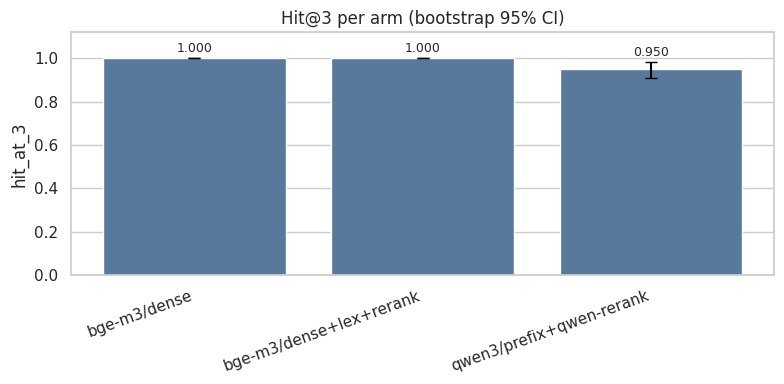

In [9]:
# ==== Part A =================================================================
phase_a_rows = []
ARM_RUNTIME_S: dict[str, float] = {}
for arm, fn in ARM_FNS.items():
    t0 = time.perf_counter()
    try:
        flags = []
        for _, p in ans.iterrows():
            gold_ids = set(p["expected_chunks"] or [])
            top3 = {cid for cid, _ in fn(p["question"])[:3]}
            flags.append(float(bool(gold_ids & top3)))
    except Exception as e:
        raise RuntimeError(f"arm `{arm}` failed in Part A (memory/time/model). Cause: {e}") from e
    ARM_RUNTIME_S[arm] = time.perf_counter() - t0
    mean, lo, hi = bootstrap_ci(flags)
    phase_a_rows.append({"arm": arm, "hit_at_3": mean, "lo": lo, "hi": hi, "flags": flags,
                         "runtime_s": ARM_RUNTIME_S[arm], **ARM_COST[arm]})

phase_a = pd.DataFrame(phase_a_rows).sort_values("hit_at_3", ascending=False).reset_index(drop=True)
BEST_ARM = phase_a.loc[0, "arm"]
best_flags = np.asarray(phase_a.loc[0, "flags"])


def passes_a(row) -> bool:
    """Best arm passes; any other arm passes if CI-lo of its paired Hit@3 difference clears the floor."""
    if row["arm"] == BEST_ARM:
        return True
    _, lo, _ = bootstrap_ci(np.asarray(row["flags"]) - best_flags)
    return lo > CRITERIA["A_CI_FLOOR"]


phase_a["passes_A"] = phase_a.apply(passes_a, axis=1)
passing = phase_a[phase_a["passes_A"]]
# Tie-break: cheapest passing arm (fewest reranker calls, then embed calls).
FINAL_ARM = min(passing["arm"], key=lambda a: (ARM_COST[a]["rerank_pairs"], ARM_COST[a]["embed_calls"],
                                               -phase_a.set_index("arm").loc[a, "hit_at_3"]))
DENSE_HIT = float(phase_a.set_index("arm").loc["bge-m3/dense", "hit_at_3"])

# Measured here, after Part A: rerankers load lazily, so their weights only exist on disk now.
ARM_DOWNLOAD_MB = {a: float(np.nansum([model_cache_mb(m) for m in ms])) for a, ms in ARM_MODELS.items()}
phase_a["download_mb"] = phase_a["arm"].map(ARM_DOWNLOAD_MB)

display(phase_a.drop(columns=["flags"]).round({"hit_at_3": 4, "lo": 4, "hi": 4, "runtime_s": 1, "download_mb": 0}))
bar_with_ci(phase_a, x="arm", y="hit_at_3", lo="lo", hi="hi", title="Hit@3 per arm (bootstrap 95% CI)")

### Reading the figure — Hit@3 per arm

One bar per arm: the height is Hit@3 — the share of the 120 answerable questions whose
gold passage is among the top 3 results — and the black whisker is its 95% bootstrap confidence interval.
Overlapping whiskers mean the arms cannot be told apart on this question set; the decision then falls to cost.

In [10]:
# ==== Part A — results =======================================================
pa = phase_a.set_index("arm")
tied = pa.index[np.isclose(pa["hit_at_3"], pa.loc[BEST_ARM, "hit_at_3"])].tolist()
speedup = pa["runtime_s"].max() / pa.loc[FINAL_ARM, "runtime_s"]

# Hit@3 by language, from the same per-probe flags (no extra model calls).
lang_rows = []
for arm, row in pa.iterrows():
    s = pd.Series(row["flags"], index=ans["language"].values)
    lang_rows.append({"arm": arm, **s.groupby(level=0).mean().round(3).to_dict()})
display(pd.DataFrame(lang_rows).set_index("arm"))

failed = [a for a in pa.index if not pa.loc[a, "passes_A"]]
show_md(
    f"- **Best Hit@3 = {pa.loc[BEST_ARM, 'hit_at_3']:.3f}**"
    + (f", shared by {len(tied)} arms ({', '.join(f'`{a}`' for a in tied)})." if len(tied) > 1 else f" (`{BEST_ARM}`).")
    + f"\n- Meeting the criterion: {', '.join(f'`{a}`' for a in passing['arm'])}. "
    + (f"Rejected: {', '.join(f'`{a}` ({pa.loc[a, 'hit_at_3']:.3f}, CI [{pa.loc[a, 'lo']:.3f}, {pa.loc[a, 'hi']:.3f}])' for a in failed)}." if failed else "")
    + f"\n- **Chosen: `{FINAL_ARM}`**"
    + (" by the cost tie-break" if len(passing) > 1 else " (the only arm meeting the criterion)")
    + f" — {ARM_COST[FINAL_ARM]['rerank_pairs']} reranker calls per query and {pa.loc[FINAL_ARM, 'runtime_s']:.1f}s "
    f"for all {len(ans)} probes, vs {pa['runtime_s'].max():.1f}s (~{speedup:.0f}×) for the slowest arm."
    + (" On this corpus the reranker adds latency without adding Hit@3."
       if len(tied) > 1 and ARM_COST[FINAL_ARM]["rerank_pairs"] == 0
       and any(ARM_COST[a]["rerank_pairs"] > 0 for a in tied) else "")
)

,en,he
arm,,
bge-m3/dense,1.000,1.000
bge-m3/dense+lex+rerank,1.000,1.000
qwen3/prefix+qwen-rerank,0.983,0.917


- **Best Hit@3 = 1.000**, shared by 2 arms (`bge-m3/dense`, `bge-m3/dense+lex+rerank`).
- Meeting the criterion: `bge-m3/dense`, `bge-m3/dense+lex+rerank`. Rejected: `qwen3/prefix+qwen-rerank` (0.950, CI [0.908, 0.983]).
- **Chosen: `bge-m3/dense`** by the cost tie-break — 0 reranker calls per query and 2.6s for all 120 probes, vs 146.5s (~56×) for the slowest arm. On this corpus the reranker adds latency without adding Hit@3.

## B · Can a search-score threshold detect "no answer"?

Idea: if the best match for a question is weak, the corpus probably doesn't contain the answer, so
the system could say "no information" **without calling the LLM**. For every probe (answerable and
unanswerable) we take the live `bge-m3/dense` results and build one composite score:

> **score = top1 + 0.5 × gap + 1.5 × overlap**
> *top1* — cosine similarity of the best chunk · *gap* — margin over the 2nd chunk (a clear winner is
> more trustworthy) · *overlap* — share of question words present in the best chunk.

A threshold is chosen on a **calibration** half (unanswerable split per language × near-miss/far,
seed 7; answerable split by a hash of the probe id), then applied unchanged to the **test** half.
Below the threshold → abstain.

**Target:** catch **≥ 80%** of unanswerable questions (*abstain_recall*) while wrongly refusing **≤ 5%** of
answerable ones (*false_abstain*), measured on the held-out half.

,metric,value,target
0,threshold,0.541,—
1,abstain_recall (test),0.3333,≥ 0.8
2,false_abstain (test),0.0882,≤ 0.05
3,meets target,False,—


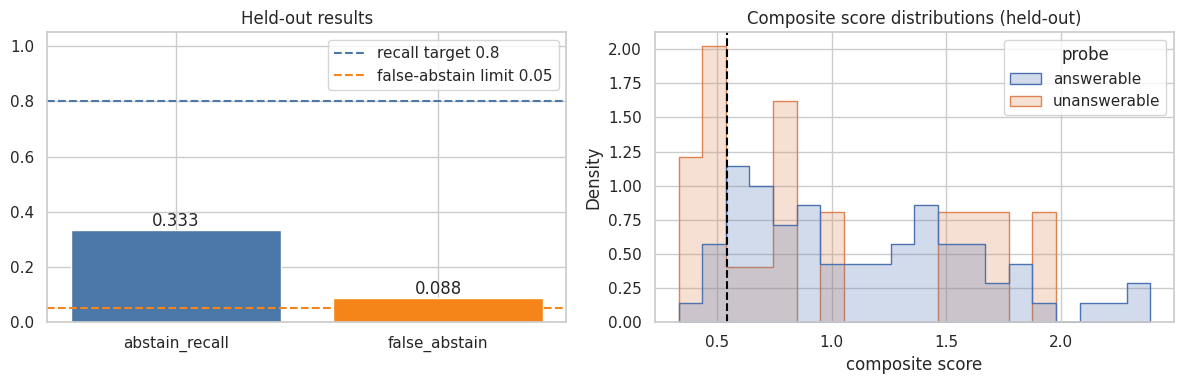

In [11]:
# ==== Part B =================================================================
rng = np.random.default_rng(CRITERIA["SPLIT_SEED"])
dense_fn = ARM_FNS["bge-m3/dense"]


def dense_signals(question: str) -> dict[str, float]:
    """top1 / gap / overlap of the live dense ranking (query embeddings are memoised from Part A)."""
    hits = dense_fn(question)
    if len(hits) < 2:
        hits = hits + [("__pad__", 0.0)]
    top1, gap = hits[0][1], hits[0][1] - hits[1][1]
    overlap = lexical_overlap(question, CHUNK_BY_ID.get(hits[0][0], {}).get("text", ""))
    return {"top1": top1, "gap": gap, "overlap": overlap}


def composite(sig: dict[str, float]) -> float:
    return sig["top1"] + 0.5 * sig["gap"] + 1.5 * sig["overlap"]


t0 = time.perf_counter()
try:
    SIG = {str(p["probe_id"]): dense_signals(p["question"]) for _, p in pd.concat([ans, una]).iterrows()}
except Exception as e:
    raise RuntimeError(f"dense signals failed in Part B. Cause: {e}") from e
PHASE_B_SIGNAL_S = time.perf_counter() - t0

# Stratified 50/50 split of unanswerable probes (language × near-miss/far), seed 7.
una_meta = una.copy()
if "kind" not in una_meta.columns or una_meta["kind"].isna().all():
    # Older probe files encode the kind only in the id.
    una_meta["kind"] = una_meta["probe_id"].map(lambda x: "near_miss" if "near" in str(x) else "far")
cal_ids, test_ids = [], []
for lang in ("he", "en"):
    for kind in ("near_miss", "far"):
        ids = list(rng.permutation(list(una_meta[(una_meta["language"] == lang) & (una_meta["kind"] == kind)]["probe_id"])))
        cal_ids += ids[: len(ids) // 2]
        test_ids += ids[len(ids) // 2:]
assert len(cal_ids) == len(test_ids) == 24, (len(cal_ids), len(test_ids))

# Answerable probes: deterministic split by sha256 parity of the id (independent of the seed).
ans_ids = sorted(ans["probe_id"])
ans_cal = [i for i in ans_ids if int(hashlib.sha256(str(i).encode()).hexdigest(), 16) % 2 == 0]
ans_test = [i for i in ans_ids if i not in set(ans_cal)]

# Threshold search on calibration only. Lexicographic objective: (meets both targets?, recall − 5·FA,
# recall, −FA) — prefer a threshold that passes; otherwise the best recall/false-abstain trade-off.
cal_un = [composite(SIG[i]) for i in cal_ids]
cal_ans = [composite(SIG[i]) for i in ans_cal]
best_t, best_key = None, (-1e9,)
for t in sorted(set(cal_un + cal_ans)):
    rec = np.mean([s < t for s in cal_un])
    fa = np.mean([s < t for s in cal_ans])
    key = (rec >= CRITERIA["B_RECALL_TARGET"] and fa <= CRITERIA["B_FALSE_ABSTAIN_MAX"], rec - 5 * fa, rec, -fa)
    if key > best_key:
        best_key, best_t = key, t
ABSTAIN_THRESHOLD = float(best_t)

# Held-out evaluation with the frozen threshold.
test_un = [composite(SIG[i]) for i in test_ids]
test_ans = [composite(SIG[i]) for i in ans_test]
abstain_recall = float(np.mean([s < ABSTAIN_THRESHOLD for s in test_un]))
false_abstain = float(np.mean([s < ABSTAIN_THRESHOLD for s in test_ans]))
passes_B = bool(abstain_recall >= CRITERIA["B_RECALL_TARGET"] and false_abstain <= CRITERIA["B_FALSE_ABSTAIN_MAX"])

display(pd.DataFrame({
    "metric": ["threshold", "abstain_recall (test)", "false_abstain (test)", "meets target"],
    "value": [round(ABSTAIN_THRESHOLD, 3), round(abstain_recall, 4), round(false_abstain, 4), passes_B],
    "target": ["—", f"≥ {CRITERIA['B_RECALL_TARGET']}", f"≤ {CRITERIA['B_FALSE_ABSTAIN_MAX']}", "—"],
}))

# Why it fails: the two score distributions overlap, so no single cut separates them.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["abstain_recall", "false_abstain"], [abstain_recall, false_abstain], color=["#4C78A8", "#F58518"])
axes[0].axhline(CRITERIA["B_RECALL_TARGET"], color="#4C78A8", ls="--", label=f"recall target {CRITERIA['B_RECALL_TARGET']}")
axes[0].axhline(CRITERIA["B_FALSE_ABSTAIN_MAX"], color="#F58518", ls="--", label=f"false-abstain limit {CRITERIA['B_FALSE_ABSTAIN_MAX']}")
for i, v in enumerate([abstain_recall, false_abstain]):
    axes[0].text(i, v, f"{v:.3f}", ha="center", va="bottom")
axes[0].set(title="Held-out results", ylim=(0, 1.05))
axes[0].legend()
dist = pd.DataFrame({"composite score": test_ans + test_un,
                     "probe": ["answerable"] * len(test_ans) + ["unanswerable"] * len(test_un)})
sns.histplot(data=dist, x="composite score", hue="probe", bins=20, stat="density", common_norm=False,
             element="step", ax=axes[1])
axes[1].axvline(ABSTAIN_THRESHOLD, color="black", ls="--", label=f"threshold {ABSTAIN_THRESHOLD:.3f}")
axes[1].set(title="Composite score distributions (held-out)")
plt.tight_layout()
plt.show()

### Reading the figure — score threshold

**Left — held-out rates.** The two held-out rates against their targets (dashed lines): the blue bar should
reach its line, the orange bar should stay under its line.

**Right — score distributions.** The distribution of the composite score for
answerable and unanswerable questions; the dashed line is the threshold. A usable threshold needs the two
distributions to sit on opposite sides of it — the more they overlap, the more any cut-off either misses
unanswerable questions or refuses answerable ones.

In [12]:
# ==== Part B — results =======================================================
un_med, ans_med = float(np.median(test_un)), float(np.median(test_ans))
ans_below_un_med = float(np.mean([s < un_med for s in test_ans]))
show_md(
    f"- With the best calibrated threshold (**{ABSTAIN_THRESHOLD:.3f}**) the held-out abstain_recall is "
    f"**{abstain_recall:.3f}** (target ≥ {CRITERIA['B_RECALL_TARGET']}) at false_abstain **{false_abstain:.3f}** "
    f"→ **target {'met' if passes_B else 'not met'}**.\n"
    f"- Median composite score: answerable {ans_med:.3f}, unanswerable {un_med:.3f}; "
    f"{ans_below_un_med:.0%} of answerable probes score below the median unanswerable probe "
    f"(see the overlap in the right-hand chart)."
    + ("\n- Because the distributions overlap, any threshold high enough to catch most unanswerable questions also "
       "refuses many answerable ones. Unanswerable questions here are about plausible company topics, so the nearest "
       "chunk is still on-topic: similarity measures *relatedness*, not whether a passage *contains the answer*.\n"
       "- **Consequence:** abstention moves to the LLM (a sufficiency check that reads the passages), evaluated in the generation notebooks."
       if not passes_B else
       "\n- A search-score threshold is sufficient for abstention on this data.")
)

- With the best calibrated threshold (**0.541**) the held-out abstain_recall is **0.333** (target ≥ 0.8) at false_abstain **0.088** → **target not met**.
- Median composite score: answerable 1.059, unanswerable 0.792; 32% of answerable probes score below the median unanswerable probe (see the overlap in the right-hand chart).
- Because the distributions overlap, any threshold high enough to catch most unanswerable questions also refuses many answerable ones. Unanswerable questions here are about plausible company topics, so the nearest chunk is still on-topic: similarity measures *relatedness*, not whether a passage *contains the answer*.
- **Consequence:** abstention moves to the LLM (a sufficiency check that reads the passages), evaluated in the generation notebooks.

## Summary

In [13]:
# ==== Summary ================================================================
RUNTIME_S = time.perf_counter() - T0_NOTEBOOK
pa_i = phase_a.set_index("arm")
tied = pa_i.index[np.isclose(pa_i["hit_at_3"], pa_i["hit_at_3"].max())].tolist()
others_tied = [a for a in tied if a != FINAL_ARM]
display(pa_i[["hit_at_3", "lo", "hi", "rerank_pairs", "runtime_s", "download_mb"]].round(
    {"hit_at_3": 3, "lo": 3, "hi": 3, "runtime_s": 1, "download_mb": 0}))
show_md(
    f"- **Retrieval method: `{FINAL_ARM}`** (Hit@3 {pa_i.loc[FINAL_ARM, 'hit_at_3']:.3f}). "
    + (f"It ties with {', '.join(f'`{a}`' for a in others_tied)} and is chosen because it is the cheapest."
       if FINAL_ARM in tied and others_tied else
       "Highest Hit@3." if FINAL_ARM in tied else
       f"Within the criterion of the best arm ({pa_i['hit_at_3'].max():.3f}) and cheaper.")
    + (f"\n- **Search score alone cannot detect unanswerable questions** (abstain_recall {abstain_recall:.3f} vs target "
       f"≥ {CRITERIA['B_RECALL_TARGET']}), so the \"no information\" decision is made by the LLM."
       if not passes_B else
       f"\n- **A search-score threshold is enough to detect unanswerable questions** (abstain_recall {abstain_recall:.3f}).")
    + f"\n- Total runtime {RUNTIME_S / 60:.1f} min on `{DEVICE}`.\n"
    "- **Limitation:** the corpus deliberately includes distractors to make search harder; production indexes only "
    "the real documents, so these numbers are a conservative estimate."
)

,hit_at_3,lo,hi,rerank_pairs,runtime_s,download_mb
arm,,,,,,
bge-m3/dense,1.00,1.000,1.000,0,2.6,8706.0
bge-m3/dense+lex+rerank,1.00,1.000,1.000,10,146.5,13080.0
qwen3/prefix+qwen-rerank,0.95,0.908,0.983,10,94.0,4606.0


- **Retrieval method: `bge-m3/dense`** (Hit@3 1.000). It ties with `bge-m3/dense+lex+rerank` and is chosen because it is the cheapest.
- **Search score alone cannot detect unanswerable questions** (abstain_recall 0.333 vs target ≥ 0.8), so the "no information" decision is made by the LLM.
- Total runtime 5.8 min on `cuda`.
- **Limitation:** the corpus deliberately includes distractors to make search harder; production indexes only the real documents, so these numbers are a conservative estimate.